In [1]:
import matplotlib as mpl
from matplotlib.lines import Line2D
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.table import Table, vstack
import matplotlib.colors as mpl_colors
from mpl_toolkits.axes_grid1 import make_axes_locatable
import numpy as np
# Tools for downloading the RSP templates
import gdown 
from pathlib import Path

In [2]:
# Read in the table of fiber-based analysis results.
tab_DAP = Table.read('DAPtable_helix.ecsv')
tab_DAP

<Table length=1754>
    id            ra         ...  X_sq_pek_9069.0    X_sq_pek_9531.1  
   str9        float64       ...      float64            float64      
--------- ------------------ ... ------------------ ------------------
   4297.3  337.4169474614286 ... 1.3629693989829357 1.8276064927905626
   4297.4 337.42638153117906 ... 0.8842719614623011 2.1337073864328078
   4297.5 337.43581492731073 ... 1.8172620083840267 3.0613251971594515
   4297.6  337.4452142099591 ...  1.616723763279993 2.0232588773532894
   4297.7 337.45464625878174 ...  7.509199158175764 20.473380194511204
   4297.8 337.46407763267024 ...  1.172444005857491  1.689329535335471
   4297.9 337.47350833118605 ...   1.03862740097424  1.850846503869197
  4297.10 337.48293835389075 ... 2.6111163308880307  12.26815153927675
  4297.11 337.49233426716734 ... 0.9827429216924148 1.3101056605935648
      ...                ... ...                ...                ...
4297.1934  337.2728561387537 ...  2.070920230862537  6.030314843047284
4297.1935 337.26344257709684 ... 1.3642844647219794  2.598939207766366
4297.1936 337.25402835385694 ... 0.8675918194967195  2.894573086157161
4297.1937 337.24464682371104 ... 1.0368766391095157  1.938330576267497
4297.1938  337.2352312798207 ...  1.252168910009903 2.9382209091159024
4297.1939  337.2258150756621 ... 1.2473028978853267  2.347903584549237
4297.1940  337.2163982116745 ...  2.424900979790681  5.359260048151733
4297.1941 337.20698068829734 ... 2.1135490558423986  5.975057048539531
4297.1942   337.197595866189 ... 3.9085183086884245  8.519790758605595
4297.1943 337.18817702654275 ...  4.065509501865053 10.124517092402334

## Properties of Stars with S/N > 5

In [3]:
SN_st = tab_DAP['med_flux_st'] / tab_DAP['e_med_flux_st']
tab_DAP['SN_st'] = SN_st
tab_DAP_st5 = tab_DAP[SN_st > 5]
print('Number of fibers with stellar S/N > 5:', len(tab_DAP_st5))

Number of fibers with stellar S/N > 5: 21


This scatter plot shows the distribution of the DAP-derived stellar metallicity proxy `[Fe/H]` and alpha-enhancement `[α/Fe]` for the selected stellar fibers. Keep in mind that those are "average" properties from a combination of stars analyzed using the RSP methodology. For a proper PDF we provide a methodology below.

For the Helix field, these points should be treated as field-star measurements.  
The Helix paper explicitly warns that the stellar results are not robust enough here to support physical conclusions about the nebula itself.

Text(0, 0.5, '[α/Fe]')

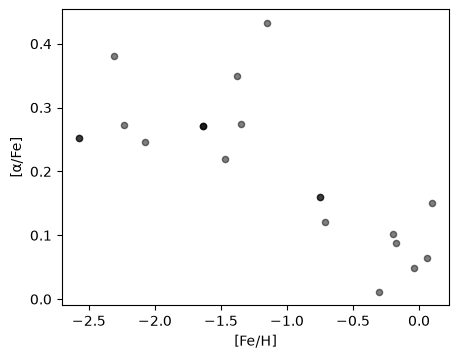

In [4]:
fig, ax = plt.subplots(1, 1, figsize=(5, 5/1.3))
ax.scatter(tab_DAP_st5['Fe'], tab_DAP_st5['alpha'], s=20, c='black', alpha=0.5)
ax.set_xlabel('[Fe/H]')
ax.set_ylabel(r'[α/Fe]')

This scatter plot shows the distribution in `Teff` versus `log g` for the selected stellar fibers.  
Again, the point is mainly diagnostic: it reveals what part of parameter space is sampled by the stars bright enough to be detected in the field.

Text(0, 0.5, 'log(g)')

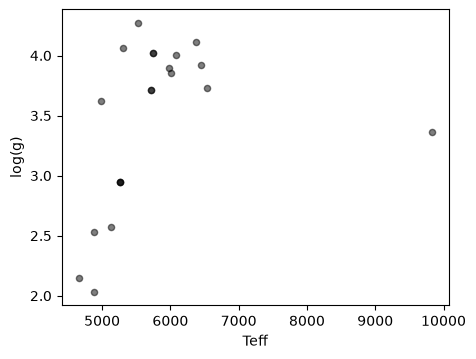

In [5]:
fig, ax = plt.subplots(1, 1, figsize=(5,5/1.3))
ax.scatter(tab_DAP_st5['Teff'], tab_DAP_st5['Log_g'], s=20, c='black', alpha=0.5)
ax.set_xlabel('Teff')
ax.set_ylabel(r'log(g)')

## Hα flux map with stellar-fiber overlay

This plot shows the Hα distribution while marking the fibers selected for the stellar analysis.  
In the Helix paper, Hα traces the overall ionized shell and the bright main ring. The overlay helps show that most stellar candidates are simply superposed on the nebular field.

The plotting function here is the same as in notebook 1.

In [6]:
def map_plot_DAP_ax(tab, ax=None, line='flux_Halpha_6562.85', title=None,
                    vmin=None, vmax=None, cmap='Spectral',
                    gamma=1.0, sf=1.0, xlab=True, ylab=True, f_scale=10):

    # By default, f_scale=10 converts units from 1e-16 erg/s/cm2/spx to 1e-15 erg/s/cm2/spx.
    
    X = tab['ra']
    Y = tab['dec']
    C = tab[line]/f_scale    
    if (title == None):
        title=line.replace("_"," ")
        title=line.replace("_"," ")

    norm = mpl_colors.PowerNorm(vmin=vmin,vmax=vmax,gamma=gamma)
    scat = ax.scatter(X, Y, s=10*sf, c=C, cmap=cmap, norm=norm, rasterized=True)

    if xlab:
        ax.set_xlabel('Ra [deg]', fontsize='x-large')
    if ylab:
        ax.set_ylabel('Dec [deg]', fontsize='x-large')
    ax.invert_xaxis()
    props = dict(boxstyle='square', facecolor='white', alpha=0.5)
    ax.text(0.05, 0.95, rf'{title}', ha='left', va='top', bbox=props, size='x-large', transform=ax.transAxes)

    return scat

Text(0, 0.5, 'Dec [deg]')

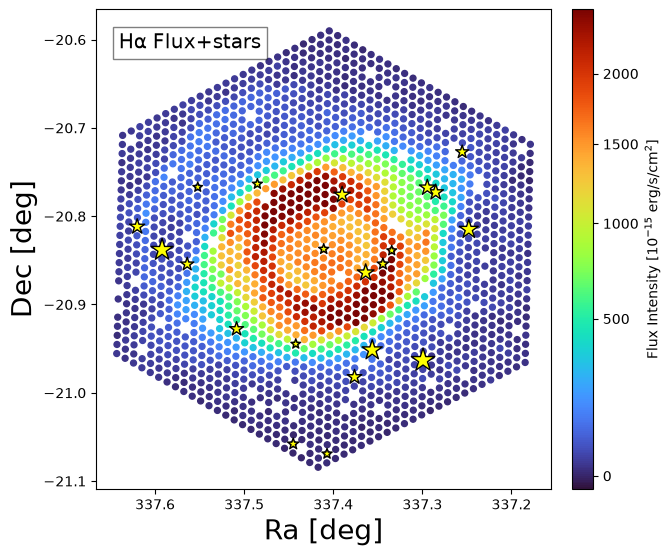

In [7]:
fig = plt.figure(figsize=(7, 6))
ax  = fig.add_axes([0.17, 0.15, 0.65, 0.8])  # left, bottom, width, height
f_scale = 10
scat = map_plot_DAP_ax(tab_DAP, ax=ax, line='flux_pek_6562.85', title=r'Hα Flux+stars',
                       vmin=-100/f_scale, vmax=24999/f_scale, cmap='turbo',
                       gamma=0.65, sf=1.8, f_scale=f_scale)

# Plot the stars, with marker size scaling with S/N
ax.scatter(tab_DAP_st5['ra'], tab_DAP_st5['dec'],
           s=10*(tab_DAP_st5['SN_st']),
           marker='*', c='yellow', edgecolor='black')

cax = fig.add_axes([0.85, 0.15, 0.03, 0.8])
cbar = fig.colorbar(scat, cax=cax, ax=ax, orientation='vertical')
cbar.set_label('Flux Intensity [10$^{-15}$ erg/s/cm$^2$]')
ax.set_xlabel('Ra [deg]',fontsize=20)
ax.set_ylabel('Dec [deg]',fontsize=20)

## RSP PDF section: focus on the few stellar fibers with high S/N

This section revisits the stellar side of the DAP, now using a stricter cut (`SN_st > 10`).  
In the Helix field, only a handful of fibers satisfy this condition. The paper stresses that these stars are not sufficient for robust conclusions about the nebula, but they are useful to demonstrate how the DAP stellar products are organized.

In [8]:
snrcut = 10
tab_DAP_st = tab_DAP[SN_st > snrcut]
print(f'Number of fibers with stellar S/N > {snrcut}: {len(tab_DAP_st)}')

Number of fibers with stellar S/N > 10: 11


## 25. Load the compact RSP library

This file contains the reduced RSP basis used by the DAP.  
Inspecting its HDU structure is useful before plotting the probability-distribution maps stored in it.

## RSP repository
A collection of RSP libraries are stored in the following google drive:
https://drive.google.com/drive/folders/1LklOobJpTsgtTlBCswkXNuhmc856XAA4?usp=drive

The RSP library used for the current analysis of the DAP is included in the INFO extension of the DAP-file.
We download the required RSP templates to explore the stellar propiertes PDFs, if they are not in the cache already.


In [9]:
def ensure_files_from_links(dir_cache, file_links):
    dir_cache = Path(dir_cache)
    dir_cache.mkdir(parents=True, exist_ok=True)

    for fname, url in file_links.items():
        out = dir_cache / fname

        if out.exists():
            print(f"Found: {fname}")
            continue

        print(f"Downloading: {fname}")
        gdown.download(url=url, output=str(out), quiet=False)

        if out.exists():
            print(f"OK: {fname}")
        else:
            print(f"FAILED: {fname}")

In [10]:
# Example usage
DIR_CACHE = 'cache'
FOLDER_URL = "https://drive.google.com/drive/folders/1LklOobJpTsgtTlBCswkXNuhmc856XAA4?usp=drive_link"

file_links = {
        "mstar-stlib-cl-108.fits.gz": "https://drive.google.com/uc?id=1RZkdshRNVi69TbVmow5sNdI2kAQokbWO",
        "mstar-stlib-n1235-SN5.fits.gz": "https://drive.google.com/uc?id=1e4vOLBBOSa6n69E4g3a3HMOhZyOPCs3f"
              }  

ensure_files_from_links(DIR_CACHE, file_links)

Found: mstar-stlib-cl-108.fits.gz
Found: mstar-stlib-n1235-SN5.fits.gz


## Content of the RSP template file

The RSP (Resolved Stellar Population) template file contains the stellar spectral library used by the LVM-DAP to model the stellar continuum. Unlike classical SSP-based libraries, these templates are constructed from combinations of observed stellar spectra, and each template is associated with a **probability distribution function (PDF)** of physical parameters rather than a single set of values. :contentReference[oaicite:0]{index=0}

The file is organized in multiple FITS extensions:

- **SPECTRA (HDU 0)**:  
  Row-stacked spectra (RSS) of the RSP templates, with dimensions *(Nwave, Ntemplate)*. Each column corresponds to one template spectrum, constructed by clustering and averaging stellar spectra in observational space.

- **PARAMETERS (HDU 1)**:  
  Table containing the **luminosity-weighted average stellar parameters** associated with each template (e.g., effective temperature, surface gravity, metallicity, and α-enhancement), derived from the underlying stellar sample.

- **ERROR (HDU 2)**:  
  Uncertainty associated with each template spectrum, propagated from the dispersion of the original stellar spectra used to construct each RSP.

- **ORG_PARAM (HDU 3)**:  
  Parameters of the original stellar library elements used to build the templates. This extension preserves the link between the final RSPs and the initial stellar population sampling.

- **PDF extensions (HDU 4–9)**:  
  These are 3D cubes containing projections of the **probability distribution functions (PDFs)** of stellar parameters for each template:
  - `PDF_TEFF_LOGG`: Teff vs log(g)
  - `PDF_TEFF_MET`: Teff vs [Fe/H]
  - `PDF_TEFF_ALPHAM`: Teff vs [α/Fe]
  - `PDF_MET_ALPHAM`: [Fe/H] vs [α/Fe]
  - `PDF_MET_LOGG`: [Fe/H] vs log(g)
  - `PDF_LOGG_MET`: log(g) vs [Fe/H]

  Each slice along the third axis corresponds to one template. These PDFs encode the intrinsic degeneracies and uncertainties of the stellar population represented by each RSP.

This structure allows the DAP to:
- model the stellar continuum using a **linear combination of templates**,  
- propagate uncertainties and degeneracies through the PDFs,  
- and derive physically meaningful stellar parameters even in regimes where only a few stars (or even a single star) are sampled within a fiber. :contentReference[oaicite:1]{index=1}

In practice, the final stellar properties for a given spectrum are obtained by combining the PDFs of the templates weighted by their fitted coefficients, rather than assigning a single best-fit value per template.

In [11]:
#################################################
# This is the RSP file used in the DAP for the stellar templates, which is required to convert the fluxes to physical units
#################################################
rsp_file=f'{DIR_CACHE}/mstar-stlib-cl-108.fits.gz'
rsp_hdu=fits.open(rsp_file)
rsp_hdu.info()

Filename: cache/mstar-stlib-cl-108.fits.gz
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  SPECTRA       1 PrimaryHDU      13   (6351, 108)   float32   
  1  PARAMETERS    1 BinTableHDU     29   108R x 10C   [D, E, E, E, E, E, E, E, E, E]   
  2  ERROR         1 ImageHDU        14   (6351, 108)   float32   
  3  ORG_PARAM     1 BinTableHDU     31   1235R x 11C   [K, E, E, E, E, E, E, E, E, E, J]   
  4  PDF_TEFF_LOGG    1 ImageHDU        17   (100, 100, 108)   float64   
  5  PDF_TEFF_MET    1 ImageHDU        17   (100, 100, 108)   float64   
  6  PDF_TEFF_ALPHAM    1 ImageHDU        17   (100, 100, 108)   float64   
  7  PDF_MET_ALPHAM    1 ImageHDU        17   (100, 100, 108)   float64   
  8  PDF_MET_LOGG    1 ImageHDU        17   (100, 100, 108)   float64   
  9  PDF_LOGG_MET    1 ImageHDU        17   (100, 100, 108)   float64   


In [12]:
in_file=f'{DIR_CACHE}/mstar-stlib-n1235-SN5.fits.gz'
hdu_in=fits.open(in_file)
hdu_in.info()

Filename: cache/mstar-stlib-n1235-SN5.fits.gz
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  SPECTRA       1 PrimaryHDU      13   (6351, 1235)   float32   
  1  PARAMETERS    1 BinTableHDU     29   1235R x 10C   [K, E, E, E, E, E, E, E, E, E]   


In [13]:
tab_in=Table(hdu_in[1].data)
tab_in

N_ST,TEFF,LOGG,MET,ALPHAM,FNORM,e_TEFF,e_LOGG,e_MET,e_ALPHAM
int64,float32,float32,float32,float32,float32,float32,float32,float32,float32
3,3.933316,4.331812,-0.95109534,-0.14910574,2.774137e-13,0.007861944,0.0701415,0.052159414,0.039048508
3,3.9932098,3.7210112,-0.3905691,-0.15078576,3.666225e-13,0.010280624,0.061887857,0.026571764,0.03762745
3,3.8498373,4.033195,-0.20987256,-0.1285125,7.4413986e-14,0.007958871,0.07636907,0.07124082,0.035553683
4,3.847179,4.0028214,-0.038304176,-0.12593675,1.1025077e-13,0.0067029507,0.04037372,0.05706607,0.016368402
3,3.893481,4.537206,0.20135541,-0.16826282,1.6679243e-14,0.0015329827,0.01214265,0.06252152,0.054127824
4,3.9733667,4.047627,0.44422022,-0.15530422,2.944137e-13,0.0015268029,0.08308116,0.05206494,0.054388586
4,3.7893019,3.709515,-2.7877254,-0.018444723,1.1454379e-15,0.001764468,0.07925614,0.050722186,0.019428022
4,3.807169,3.773035,-2.7579265,0.035485208,1.2067869e-15,0.0071557313,0.08064561,0.02180943,0.015435792
3,3.7883403,3.861594,-2.38736,-0.0104874605,2.1706814e-15,0.006465776,0.004503704,0.04713469,0.0308652


## 26. Convert the per-fiber RSP columns into a long-format coefficient table

The DAP stores the RSP results in a wide format, with many columns carrying the RSP identifier in the column name.  
This helper function inverts that structure into a long table with one row per `(fiber, rsp)` pair, making it much easier to inspect:
- coefficients (i.e., the light contribution of each RSP template to the stellar continuum),

- template stellar parameters (Teff, log(g), [Fe/H], [alpha/Fe])

In [14]:
coeff_rename = {
    'Teff_rsp':    'TEFF',
    'Log_g_rsp':   'LOGG',
    'Fe_rsp':      'META',
    'alpha_rsp':   'ALPHAM',
    'W_rsp':       'COEFF',
    'min_W_rsp':   'Min.Coeff',
    'log_ML_rsp':  'log(M/L)',
    'Av_rsp':      'AV',
    'n_W_rsp':     'N.Coeff',
    'e_W_rsp':     'Err.Coeff',
}

def invert_transformation(tab):
    """Convert wide table (one set of columns per RSP) to long format."""
    rsp_ids = sorted({c.rsplit('_', 1)[1] for c in tab.colnames
                      if c.startswith('Teff_rsp_')}, key=int)

    # Create set of rows for each fiber
    id_fib = [int(s.split('.')[1]) for s in tab['id']]

    tables = []
    for rsp_id in rsp_ids:
        suffix = f'_{rsp_id}'
        cols = [c for c in tab.colnames if c.endswith('rsp'+suffix)]
        base = [c[:-len(suffix)] for c in cols]

        sub = Table([tab['id']] + [tab[c] for c in cols],
                    names=['id'] + [coeff_rename.get(b, b) for b in base])
        sub['rsp'] = int(rsp_id)
        sub['id_fib'] = id_fib
        tables.append(sub)
    return vstack(tables)

This applies the transformation to the selected stellar subset, creating the tab_coeffs table used in the PDF plots.

In [15]:
tab_DAP_st

<Table length=11>
    id            ra         ...  X_sq_pek_9531.1         SN_st       
   str9        float64       ...      float64            float64      
--------- ------------------ ... ------------------ ------------------
 4297.224 337.50852244124655 ... 12.576456328881113 11.109151118653914
 4297.519 337.59213068807105 ... 1.2941364075975106  27.26960792912486
 4297.589  337.6200581142667 ... 1.6220969673825159 13.069077624997297
 4297.819  337.2478762548075 ...  6.053565526308656  20.40925116896931
 4297.888  337.2850291772686 ...  24.15744028127017 14.010165826748347
 4297.990 337.36363095760566 ...  54.64433539840327 16.137248421912822
4297.1082 337.35625730138355 ... 2.3483441699397427 23.260139185560643
4297.1115  337.3761429656673 ...  1.288323629530389 12.111477334781942
4297.1144  337.2992377886743 ... 1.7165471740818117 31.120914439768725
4297.1648    337.39005306831 ...  109.2759640107434 15.250341264115916
4297.1706 337.29444839715546 ...  38.62039659183544 14.315081123369213

In [16]:
tab_coeffs = invert_transformation(tab_DAP_st)

In [17]:
tab_coeffs

id,TEFF,LOGG,META,ALPHAM,COEFF,Min.Coeff,log(M/L),AV,N.Coeff,Err.Coeff,rsp,id_fib
str9,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,int64,int64
4297.224,3.8065,4.0113,-2.0998,0.3273,0.0,0.0,14.6447,0.0,0.0,0.0,0,224
4297.519,3.8065,4.0113,-2.0998,0.3273,0.0,0.0,14.6447,0.09,0.0,0.0,0,519
4297.589,3.8065,4.0113,-2.0998,0.3273,0.0,0.0,14.6447,0.09,0.0,0.0,0,589
4297.819,3.8065,4.0113,-2.0998,0.3273,0.0,0.0,14.6447,0.09,0.0,0.0,0,819
4297.888,3.8065,4.0113,-2.0998,0.3273,0.0,0.0,14.6447,0.09,0.0,0.0,0,888
4297.990,3.8065,4.0113,-2.0998,0.3273,0.0,0.0,14.6447,0.09,0.0,0.0,0,990
4297.1082,3.8065,4.0113,-2.0998,0.3273,0.0,0.0,14.6447,0.18,0.0,0.0,0,1082
4297.1115,3.8065,4.0113,-2.0998,0.3273,0.0,0.0,14.6447,0.18,0.0,0.0,0,1115
4297.1144,3.8065,4.0113,-2.0998,0.3273,0.0,0.0,14.6447,0.06,0.0,0.0,0,1144


## 29. Build an average coefficient representation

This cell groups the coefficients by RSP and computes a mean table.  
It is effectively a way to build an average PDF representation across the selected sample.

In [18]:
# Exclude non-numeric columns like 'id'
num_cols = [c for c in tab_coeffs.colnames
            if c not in ('rsp', 'id', 'id_fib') 
            and tab_coeffs[c].dtype.kind in 'biuf']

mean_table = (tab_coeffs[['rsp'] + num_cols]
                .group_by('rsp')
                .groups.aggregate(np.mean))

mean_table

rsp,TEFF,LOGG,META,ALPHAM,COEFF,Min.Coeff,log(M/L),AV,N.Coeff,Err.Coeff
int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64
0,3.8065,4.011299999999999,-2.0998000000000006,0.32730000000000004,0.0,0.0,14.6447,0.09,0.0,0.0
1,3.7847000000000004,3.7481000000000004,-1.3644,0.32669999999999993,0.0,0.0,14.413800000000002,0.09,0.0,0.0
2,3.6625999999999994,1.7684,-1.3138000000000003,0.2218,0.0,0.0,13.753000000000002,0.09,0.0,0.0
3,3.7832999999999997,4.2391,-0.2624,0.09140000000000001,0.0,0.0,13.404500000000002,0.09,0.0,0.0
4,3.682900000000001,3.8664,0.019999999999999997,0.037899999999999996,0.0,0.0,13.415899999999999,0.09,0.0,0.0
5,3.661500000000001,4.593600000000001,-0.0338,0.023799999999999998,0.0,0.0,13.9712,0.09,0.0,0.0
6,3.7571,3.7104,-0.7526,0.15969999999999998,0.18181818181818182,0.0,13.986199999999998,0.09,0.18181818181818182,0.0
7,3.6111999999999993,1.292,-0.8048000000000001,0.11210000000000003,0.0,0.0,13.206999999999999,0.09,0.0,0.0
8,3.7213,2.9467,-1.6333999999999997,0.27090000000000003,0.18181818181818182,0.0,13.9755,0.09,0.18181818181818182,0.0


## 27. Helper functions for RSP PDF plots

These functions:
- derive contour levels from the template-density maps,
- and overlay the weighted PDF implied by one selected fiber.

This section is the notebook counterpart to the stellar-PDF figure in the Helix paper, where the recovered stellar properties are compared with the full distribution of the template library.

In [19]:
DEFAULT_CONTS = (0.99, 0.65, 0.40)

# ----------------------------------------------------------------------------
# Core helpers
# ----------------------------------------------------------------------------
def get_den_levels(den_map, conts=DEFAULT_CONTS):
    """Contour thresholds (in units of the peak) enclosing the fractions `conts`
    of the total density. Returns increasing levels and the peak-normalised map.
    A fraction of 0.0 maps to the peak (1.0), giving contourf an upper bound."""
    p = np.asarray(den_map, dtype=float)
    p = p / np.nanmax(p)
    flat = np.sort(np.clip(p[np.isfinite(p)], 0, None).ravel())[::-1]
    cum = np.cumsum(flat)
    cum /= cum[-1]
    levels = np.interp(conts, cum, flat)
    return np.unique(levels), p          # unique -> strictly increasing


def _axis_coords(header, n, axis):
    """Pixel centres and outer edges along FITS axis 1 (x) or 2 (y)."""
    crval, cdelt = header[f'CRVAL{axis}'], header[f'CDELT{axis}']
    crpix = header.get(f'CRPIX{axis}', 1.0)
    centres = crval + (np.arange(n) + 1 - crpix) * cdelt
    return centres, (centres[0] - 0.5 * cdelt, centres[-1] + 0.5 * cdelt)


def _grid(hdu):
    _, ny, nx = hdu.data.shape
    xc, xl = _axis_coords(hdu.header, nx, 1)
    yc, yl = _axis_coords(hdu.header, ny, 2)
    return xc, yc, (*xl, *yl)


def _weighted_map(data, weights):
    w = np.asarray(weights, dtype=float)
    if w.size != data.shape[0]:
        raise ValueError(f'{w.size} weights for {data.shape[0]} planes')
    return np.tensordot(w, data, axes=1) / w.sum()


def _draw_background(ax, data, extent, conts, den_map=None):
    """Grey image + black contours of the mean map (reused if passed in)."""
    if den_map is None:
        den_map = data.mean(axis=0)
    ax.imshow(den_map, extent=extent, cmap='Greys', origin='lower', aspect='auto')
    levels, p = get_den_levels(den_map, conts)
    ax.contour(p, levels, colors='k', origin='lower', extent=extent)
    return den_map


def _draw_pdf(ax, z, extent, conts, color, fill_alpha=0.3):
    """Coloured contour lines + translucent fill for one PDF map."""
    color = mpl.colors.to_hex(color, keep_alpha=True)
    levels, p = get_den_levels(z, conts)
    kw = dict(colors=[color], origin='lower', extent=extent)
    ax.contour(p, levels, **kw)
    if fill_alpha:
        ax.contourf(p, levels, alpha=fill_alpha, **kw)

# ----------------------------------------------------------------------------
# Public functions
# ----------------------------------------------------------------------------
def PDF_get(hdu_now=None, n_fib=None, tab_coeffs=None, **_unused):
    """COEFF-weighted average map for one fibre.
    Assumes the selected rows are ordered like the cube's z-axis."""
    w = tab_coeffs['COEFF'][tab_coeffs['id_fib'] == n_fib]
    return _weighted_map(hdu_now.data, w)


def PDF_plot(ax=None, hdu_now=None, xlabel=None, ylabel=None,
             n_fib=None, tab_coeffs=None, conts=DEFAULT_CONTS,
             color_PDF='tomato', pXhist=False, pYhist=False, den_map=None):
    """Mean map in grey/black plus one fibre's PDF, with optional marginals.
    Pass `den_map` (returned by a previous call) to skip recomputing the mean."""
    xc, yc, extent = _grid(hdu_now)
    den_map = _draw_background(ax, hdu_now.data, extent, conts, den_map)
    den_map_few = PDF_get(hdu_now, n_fib, tab_coeffs)
    _draw_pdf(ax, den_map_few, extent, conts, color_PDF)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)

    if pXhist or pYhist:
        divider = make_axes_locatable(ax)
    if pXhist:
        h = den_map_few.sum(axis=0)
        axX = divider.append_axes('top', 0.35, pad=0.0, sharex=ax)
        axX.plot(xc, h, color=color_PDF)
        axX.set_ylim(0.001 * h.max(), 1.01 * h.max())
        axX.axis('off')
    if pYhist:
        h = den_map_few.sum(axis=1)
        axY = divider.append_axes('right', 0.35, pad=0.0, sharey=ax)
        axY.plot(h, yc, color=color_PDF)
        axY.set_xlim(0.001 * h.max(), 1.01 * h.max())
        axY.axis('off')
    return den_map, den_map_few


def PDF_plot_cl(ax=None, hdu_now=None, xlabel=None, ylabel=None,
                n_fibs=None, conts=DEFAULT_CONTS, cmap='Spectral',
                c_cut=0.8, den_map=None, legend=False):
    """Mean map plus the single planes hdu_now.data[n_fib] for each n_fib,
    coloured along `cmap`. Returns the mean map and legend handles."""
    _, _, extent = _grid(hdu_now)
    den_map = _draw_background(ax, hdu_now.data, extent, conts, den_map)

    hash_ = r'\#' if mpl.rcParams['text.usetex'] else '#'
    colors = mpl.colormaps[cmap](np.linspace(0, c_cut, len(n_fibs)))
    handles = []
    for n_fib, c in zip(n_fibs, colors):
        _draw_pdf(ax, hdu_now.data[n_fib], extent, conts, c)
        handles.append(Line2D([], [], color=c, label=f'{hash_}{n_fib}'))

    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    if legend:
        ax.legend(handles=handles)
    return den_map, handles


This prints the available fiber IDs in the transformed coefficient table, helping select example fibers for the PDF plots.

This is a first test of the PDF plotting function for one projection of the parameter space.  
It is useful for checking axis ranges, contour levels, and consistency between the recovered coefficients and the template library.

It shows the general PDF distribution for the full MaStar catalog compared with the PDF for fiber 519

Here we plot the PDF of $[\alpha/Fe]$ vs $[Fe/H]$: the library in black, and the solutions for two fibers in red.

In [20]:
# Choose a fiber to plot.  These are the ones with S/N > 10.
n_fiber = [int(s.split('.')[1]) for s in np.array(tab_DAP_st['id'])]
print(n_fiber)

[224, 519, 589, 819, 888, 990, 1082, 1115, 1144, 1648, 1706]


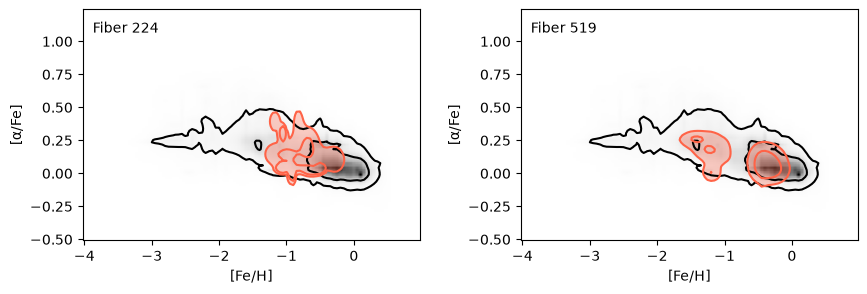

In [21]:
hdu_now=rsp_hdu['PDF_MET_ALPHAM']
xlabel=r'[Fe/H]'
ylabel=r'[α/Fe]'

fig, (ax1,ax2) = plt.subplots(1, 2, figsize=(10,3))  
_ = PDF_plot(ax=ax1, hdu_now=hdu_now, xlabel=xlabel, ylabel=ylabel, n_fib=n_fiber[0], 
         tab_coeffs=tab_coeffs, conts=[0.85,0.40,0.0])  
ax1.text(0.03, 0.9, f'Fiber {n_fiber[0]}', transform=ax1.transAxes)
_ = PDF_plot(ax=ax2, hdu_now=hdu_now, xlabel=xlabel, ylabel=ylabel, n_fib=n_fiber[1], 
         tab_coeffs=tab_coeffs, conts=[0.85,0.40,0.0])  
ax2.text(0.03, 0.9, f'Fiber {n_fiber[1]}', transform=ax2.transAxes)
fig.subplots_adjust(wspace=0.3)

## 28. Multi-panel stellar PDF figure for one fiber

This figure is one of the closest notebook analogs to the stellar-PDF plot discussed in the Helix paper.  
It shows how the coefficients for one selected fiber project onto different parameter planes:
- `Teff` vs `log g`
- `Teff` vs `[α/Fe]`
- `[Fe/H]` vs `[α/Fe]`
- `[Fe/H]` vs `log g`

The overplotted star marks the luminosity-weighted values derived by the DAP.  
The main lesson for the Helix is again caution: the DAP can produce these stellar products, but the stellar signal in this field is too limited for strong astrophysical conclusions.

In [22]:
def corner_PDF(n_fib, rsp_hdu, tab_coeffs, tab_dap, conts=(0.99,0.65,0.35,0.00),
               star_kw=None):
    """2x2 panel: columns = log Teff, [Fe/H]; rows = log g (top), [α/Fe] (bottom)."""
    fig, axs = plt.subplots(2, 2, figsize=(8.5, 6), sharex='col', sharey='row',
                            gridspec_kw=dict(hspace=0, wspace=0,
                                             left=0.15, right=0.85, bottom=0.15, top=0.85))

    row = tab_dap[tab_dap['fiberid'] == n_fib]
    cols = {'teff': np.log10(row['Teff']), 'fe': row['Fe'],
            'logg': row['Log_g'], 'alpha': row['alpha']}
    labels = {'teff': r'log(T$_{\rm eff}$)', 'fe': r'[Fe/H]',
              'logg': r'log(g)', 'alpha': r'[$\alpha$/Fe]'}
    # (row, col): (HDU extension, x key, y key)
    panels = {(0, 0): ('PDF_TEFF_LOGG',   'teff', 'logg'),
              (1, 0): ('PDF_TEFF_ALPHAM', 'teff', 'alpha'),
              (0, 1): ('PDF_MET_LOGG',    'fe',   'logg'),
              (1, 1): ('PDF_MET_ALPHAM',  'fe',   'alpha')}

    star_kw = dict(color='deepskyblue', edgecolor='blue', marker='*',
                   s=100, zorder=1000) | (star_kw or {})
    for (i, j), (ext, xk, yk) in panels.items():
        ax = axs[i, j]
        PDF_plot(ax=ax, hdu_now=rsp_hdu[ext], n_fib=n_fib, tab_coeffs=tab_coeffs,
                 conts=conts,
                 xlabel=labels[xk] if i == 1 else '',
                 ylabel=labels[yk] if j == 0 else '',
                 pXhist=(i == 0),   # top row
                 pYhist=(j == 1))   # right column
        ax.scatter(cols[xk], cols[yk], **star_kw)
        #ax.set_xlim(xlims[j])
    return fig, axs

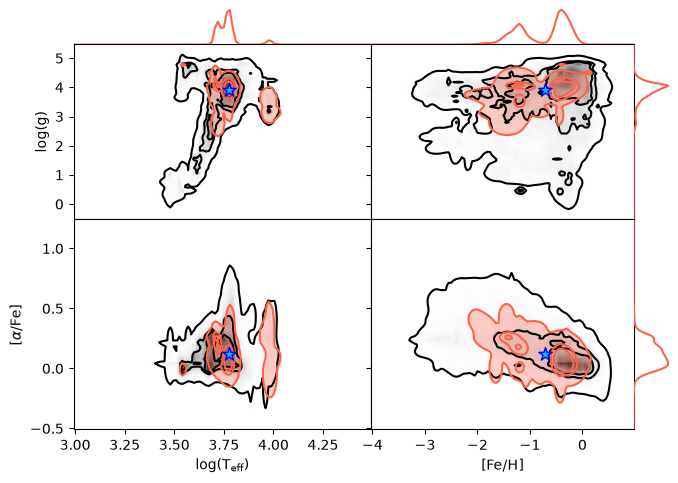

In [23]:
fig, axs = corner_PDF(519, rsp_hdu, tab_coeffs, tab_DAP_st)
plt.show()

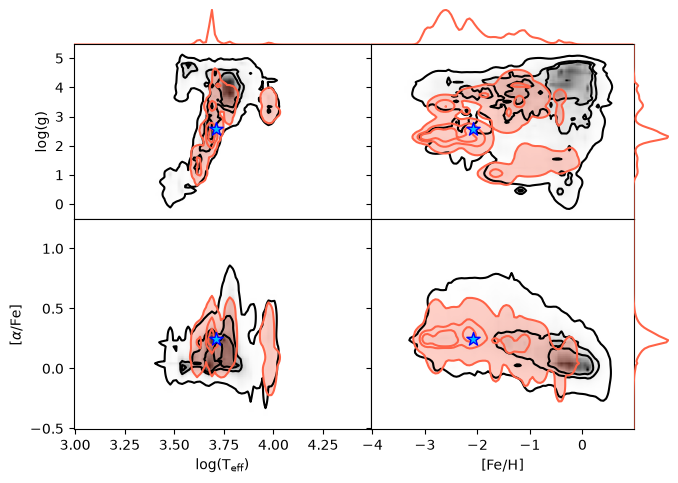

In [24]:
fig, axs = corner_PDF(1144, rsp_hdu, tab_coeffs, tab_DAP_st)
plt.show()

### About this notebook

This notebook was recreates plots included on Sánchez et al. 2025 (https://ui.adsabs.harvard.edu/abs/2026RMxAA..62...87S/) on the Helix Nebula (NGC7293) using the output of the LVM DAP (https://github.com/sdss/lvmdap).

**Authors**: Sebastian F. Sanchez, Tony Wong, Claude, and the LVM team

**Last Update**: 2026 October 9

If you use `astropy`  for published research, please cite the
authors. Follow this link for more information about citing `astropy`:

* [Citing `astropy`](https://www.astropy.org/acknowledging.html)

And of course please [cite](https://sdss.org/collaboration/citing-sdss/) SDSS when you use our data.